In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt

In [8]:
from BlackScholes import BlackScholes

model_bs = BlackScholes()

# Data

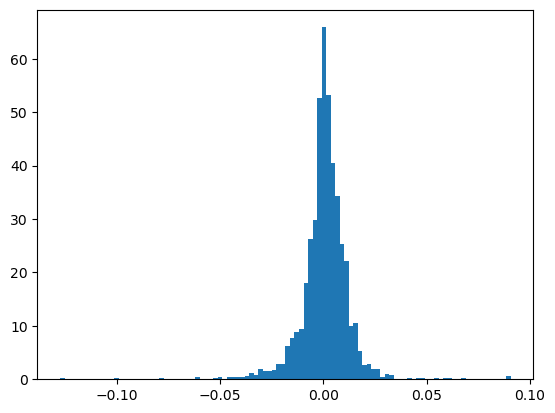

In [9]:
model_bs.plot_Y()

# Priors

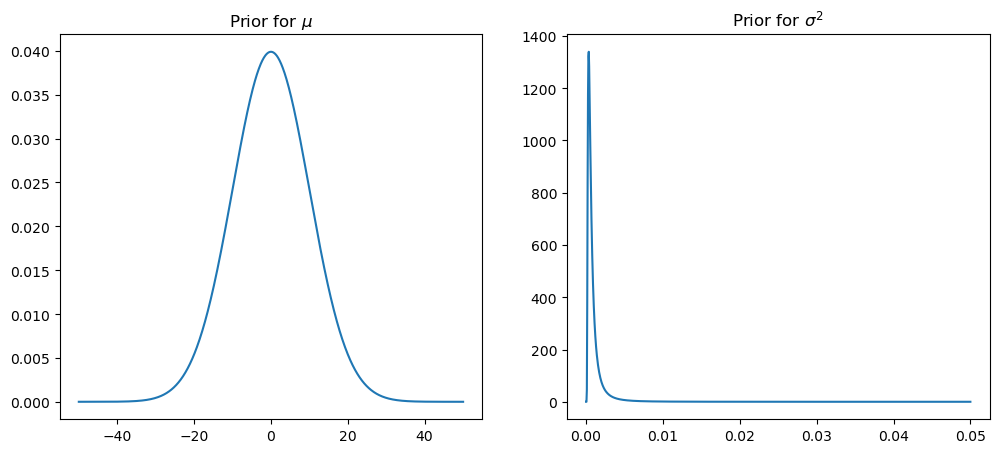

In [15]:
prior_dict = {
    'mu' : {'mu_p' : 0, 'sigma_sq_p' : 100}, # mu sim N(0, 100^2)
    'sigma_sq' : {'alpha_p' : 2, 'beta_p' : 0.001} # sigma_sq sim IG(2, 0.001)
}

model_bs.setup_priors(prior_dict)

model_bs.plot_priors()

# Likelihood and posterior

The shared likelihood-function between $(\mu, \sigma)$ is:
\begin{align*}
\ell(\mu, \sigma^2) &= \left( \frac{1}{\sqrt{2 \pi \sigma^2}} \right)^T \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}\right) \propto \left( \frac{1}{\sigma} \right)^T \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}\right)
\end{align*}
, whereby the posterior for $\mu$ given $\sigma^2$ becomes:
$$\Rightarrow p(\mu \vert \sigma^2, y) \propto \left( \frac{1}{\sigma} \right)^T  \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}\right) \left( \frac{1}{\sigma_\mu} \right)^T  \exp \left(-\frac{(\mu-\mu_\mu)^2}{2\sigma_\mu^2} \right)=\left( \frac{1}{\sigma \sigma_\mu} \right)^T \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}-\frac{(\mu-\mu_\mu)^2}{2\sigma_\mu^2}\right)$$
, which can be shown to be $\mu \vert \sigma^2, y \sim \mathcal{N} \left( \mu_N, \sigma^2_N \right)$ with $\sigma^2_N = \left( \frac{T}{\sigma^2} + \frac{1}{\sigma^2_\mu} \right)^{-1}$ and $\mu_N = \sigma^2_N \left( \frac{\sum_{t=1}^T y_t}{\sigma^2} + \frac{\mu_\mu}{\sigma^2_\mu} \right)$.

Similarly the posterior for $\sigma^2$ given $\mu$ becomes: $\sigma^2 \vert y, \mu \sim \mathcal{IG}(\alpha_N, \beta_N)$ with $\alpha_N=\alpha_{\sigma^2}+\frac{T}{2}$ and $\beta_N=\beta_{\sigma^2} + \frac{1}{2} \sum_{t=1}^T {(y_t-\mu)^2}$

# Gibbs Sampler

In [101]:
def Gibbs_step(sigma_sq_lag):

    # compute parameters for mu
    mu_mu = mu_N(Y, T, sigma_sq_lag, prior_mu_mu, prior_mu_sigma_sq)
    mu_sigma_sq = sigma_sq_N(T, sigma_sq_lag, prior_mu_sigma_sq)

    # draw mu given sigma_sq_lag
    mu_draw = np.random.normal(loc=mu_mu, scale=np.sqrt(mu_sigma_sq))

    # compute parameters for sigma
    sigma_sq_alpha = alpha_N(T, prior_sigma_alpha)
    sigma_sq_beta = beta_N(Y, mu_draw, prior_sigma_beta)

    # draw sigma given mu draw
    sigma_sq_draw = st.invgamma.rvs(a=sigma_sq_alpha, scale=sigma_sq_beta)

    return mu_draw, sigma_sq_draw

def do_Gibbs_chain(K, sigma_sq_init, burn_in=10):

    # allocate
    mus = np.zeros(K) + np.nan
    sigma_sqs = np.zeros(K) + np.nan

    # do burn-in
    sigma_sq_pre = sigma_sq_init
    for k_pre in range(burn_in):
        _, sigma_sq_pre = Gibbs_step(sigma_sq_pre)

    # chain
    for k in range(K):
        if k==0:
            sigma_sq_lag = sigma_sq_pre

        mus[k], sigma_sqs[k] = Gibbs_step(sigma_sq_lag)
        sigma_sq_lag = sigma_sqs[k]

    return mus, sigma_sqs

In [102]:
sigma_sq_init = np.var(Y)
mus, sigma_sqs = do_Gibbs_chain(100_000, sigma_sq_init)

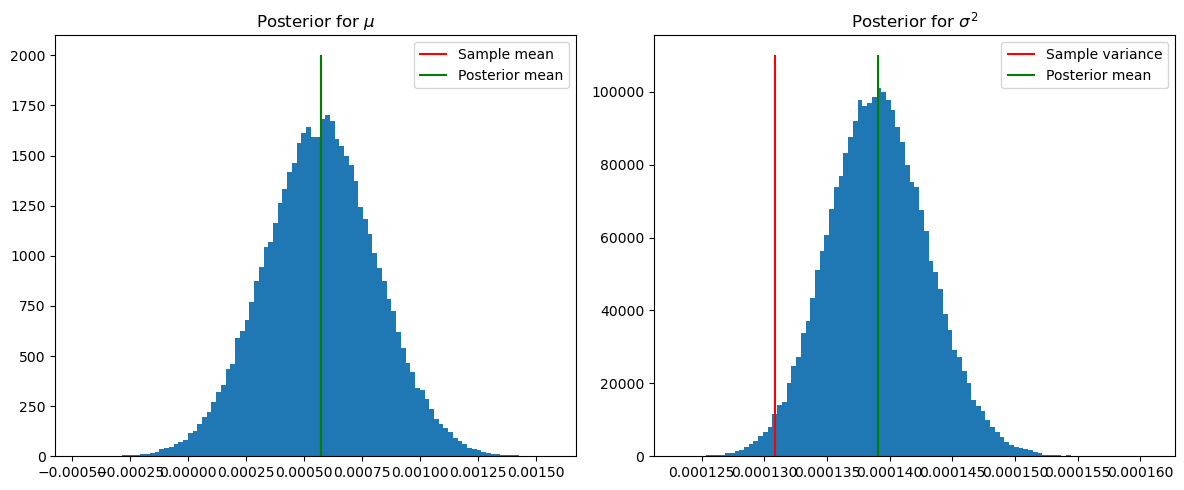

In [114]:
f, ax = plt.subplots(1,2,figsize=(12,5))

ax[0].hist(mus, bins=100, density=True)
ax[1].hist(sigma_sqs, bins=100, density=True)

ax[0].vlines(np.mean(Y), 0, 2000, color='red', label='Sample mean')
ax[1].vlines(np.var(Y), 0, 110_000, color='red', label='Sample variance')

ax[0].vlines(np.mean(mus), 0, 2000, color='green', label='Posterior mean')
ax[1].vlines(np.mean(sigma_sqs), 0, 110_000, color='green', label='Posterior mean')

ax[0].set_title(r'Posterior for $\mu$')
ax[1].set_title(r'Posterior for $\sigma^2$')

for i in range(2): ax[i].legend()

f.tight_layout()

In [83]:
np.std(Y)

np.float64(0.011440103316508937)